In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
ks_table = pd.read_csv("data/processed/ks_table.csv")
boot_table = pd.read_csv("data/processed/boot_table.csv")

## Summary statistic table

In [4]:
# Create the descriptive-statistics table.
# This uses sample sizes and medians already calculated in boot_table.
descriptive_rows = []

for _, row in boot_table.iterrows():

    # Add one row for public firms.
    descriptive_rows.append(
        {
            "Year": row["Year"],
            "Group": "Public",
            "Measure": row["Measure"],
            "Number of firms": row["n_public"],
            "Median (USD millions)": row["M_public"],
        }
    )

    # Add one row for private firms.
    descriptive_rows.append(
        {
            "Year": row["Year"],
            "Group": "Private",
            "Measure": row["Measure"],
            "Number of firms": row["n_private"],
            "Median (USD millions)": row["M_private"],
        }
    )

# Turn the collected rows into a table.
descriptive_table = pd.DataFrame(descriptive_rows)

# Put the rows in a logical order.
descriptive_table = descriptive_table.sort_values(
    by=["Measure", "Year", "Group"]
)

# Save the descriptive-statistics table.
descriptive_table.to_csv(
    "outputs/tables/descriptive_statistics.csv",
    index=False,
)

In [5]:
print(descriptive_table.round(3))

    Year    Group       Measure  Number of firms  Median (USD millions)
1   2021  Private       Revenue            26806                  1.033
0   2021   Public       Revenue              477                 57.318
5   2022  Private       Revenue            26989                  1.199
4   2022   Public       Revenue              478                 64.924
9   2023  Private       Revenue            23245                  1.606
8   2023   Public       Revenue              478                 64.328
13  2024  Private       Revenue            23122                  1.633
12  2024   Public       Revenue              479                 63.130
17  2025  Private       Revenue            22719                  1.752
16  2025   Public       Revenue              479                 63.288
3   2021  Private  Total assets            33015                  2.339
2   2021   Public  Total assets              479                111.518
7   2022  Private  Total assets            33042                

## Median Line Chart

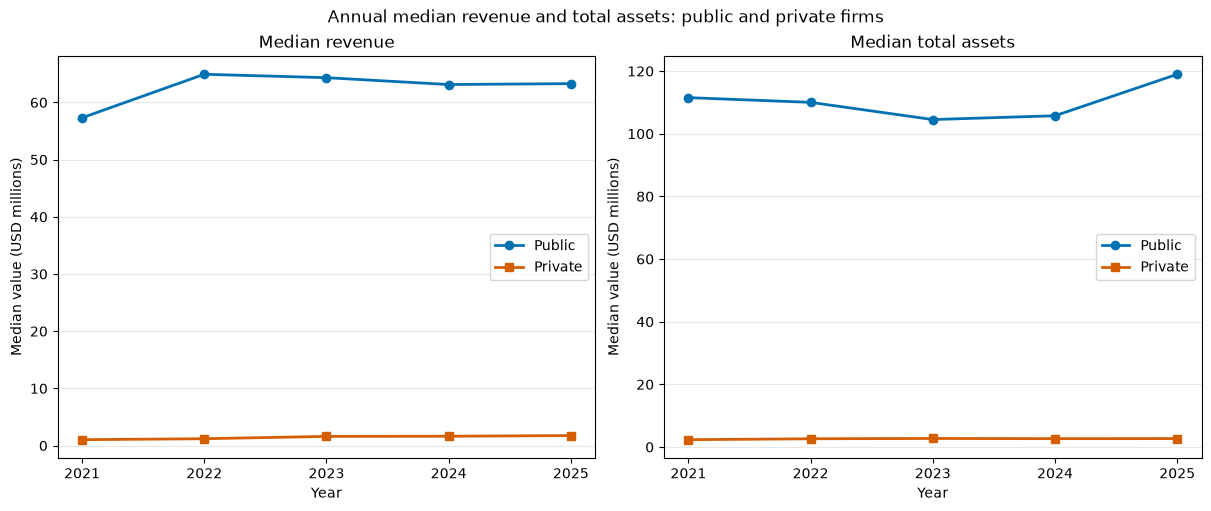

In [6]:
boot_table = pd.read_csv("data/processed/boot_table.csv")

# Create two chart panels: one for revenue and one for total assets.
fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(12, 5),
    constrained_layout=True,
)

# Create one chart for each financial measure.
for ax, measure in zip(axes, ["Revenue", "Total assets"]):

    # Keep only rows for the current measure.
    subset = boot_table[
        boot_table["Measure"] == measure
    ].sort_values("Year")

    # Plot public-company annual medians.
    ax.plot(
        subset["Year"],
        subset["M_public"],
        label="Public",
        color="#0072B2",
        marker="o",
        linewidth=2,
    )

    # Plot private-company annual medians.
    ax.plot(
        subset["Year"],
        subset["M_private"],
        label="Private",
        color="#D55E00",
        marker="s",
        linewidth=2,
    )

    # Add labels and styling.
    ax.set_title(f"Median {measure.lower()}")
    ax.set_xlabel("Year")
    ax.set_ylabel("Median value (USD millions)")
    ax.set_xticks([2021, 2022, 2023, 2024, 2025])
    ax.grid(axis="y", alpha=0.3)
    ax.legend()

fig.suptitle(
    "Annual median revenue and total assets: public and private firms"
)

# Save a high-quality image and a PDF version.
plt.savefig(
    "outputs/figures/median_line_charts.png",
    dpi=300,
    bbox_inches="tight",
)


## Confidence interval Charts

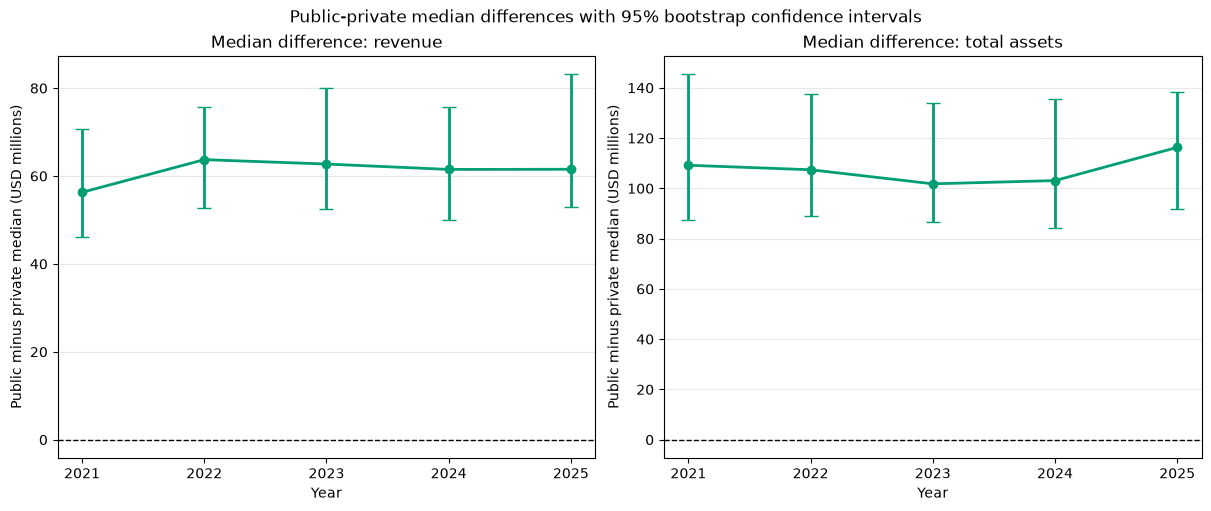

In [7]:
boot_table = pd.read_csv("data/processed/boot_table.csv")

# Create two chart panels.
fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(12, 5),
    constrained_layout=True,
)

# Create one confidence-interval chart for each measure.
for ax, measure in zip(axes, ["Revenue", "Total assets"]):

    # Keep only the rows for this measure.
    subset = boot_table[
        boot_table["Measure"] == measure
    ].sort_values("Year")

    # Calculate the lower and upper error-bar lengths.
    lower_error = subset["Difference"] - subset["CI_low_95"]
    upper_error = subset["CI_high_95"] - subset["Difference"]

    # Plot the median difference and its 95% confidence interval.
    ax.errorbar(
        subset["Year"],
        subset["Difference"],
        yerr=[lower_error, upper_error],
        fmt="o-",
        color="#009E73",
        linewidth=2,
        capsize=5,
    )

    # Add a line showing zero difference between groups.
    ax.axhline(
        y=0,
        color="black",
        linestyle="--",
        linewidth=1,
    )

    # Add labels and styling.
    ax.set_title(f"Median difference: {measure.lower()}")
    ax.set_xlabel("Year")
    ax.set_ylabel("Public minus private median (USD millions)")
    ax.set_xticks([2021, 2022, 2023, 2024, 2025])
    ax.grid(axis="y", alpha=0.3)

fig.suptitle(
    "Public-private median differences with 95% bootstrap confidence intervals"
)

# Save the figure.
plt.savefig(
    "outputs/figures/median_difference_confidence_intervals.png",
    dpi=300,
    bbox_inches="tight",
)

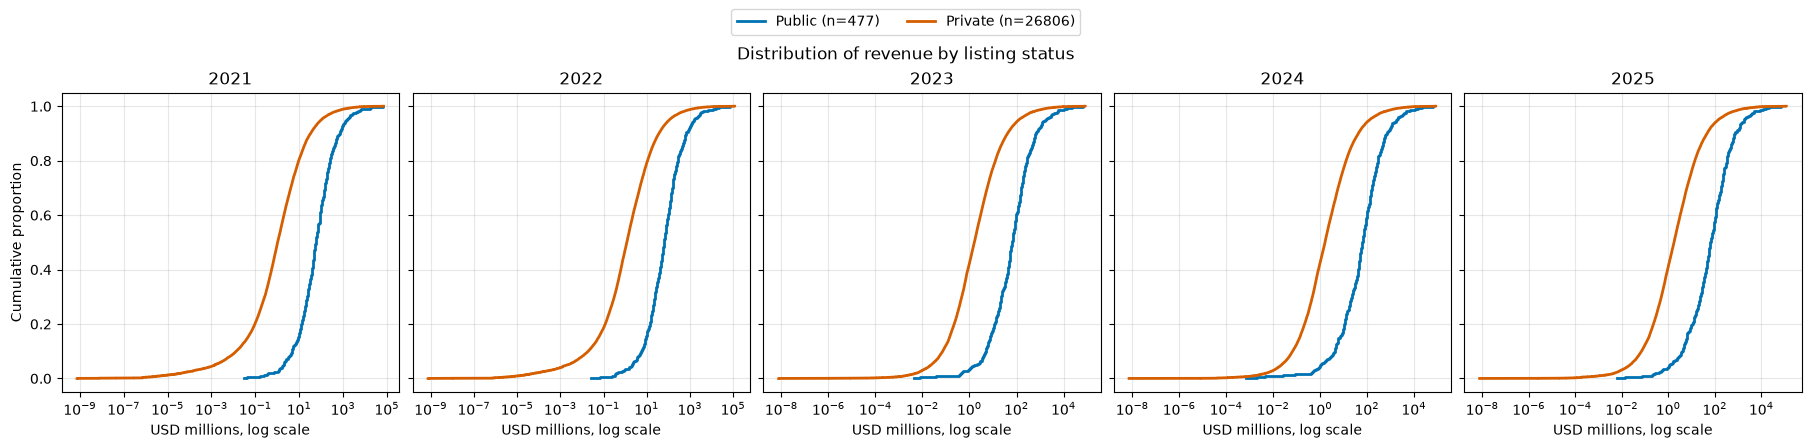

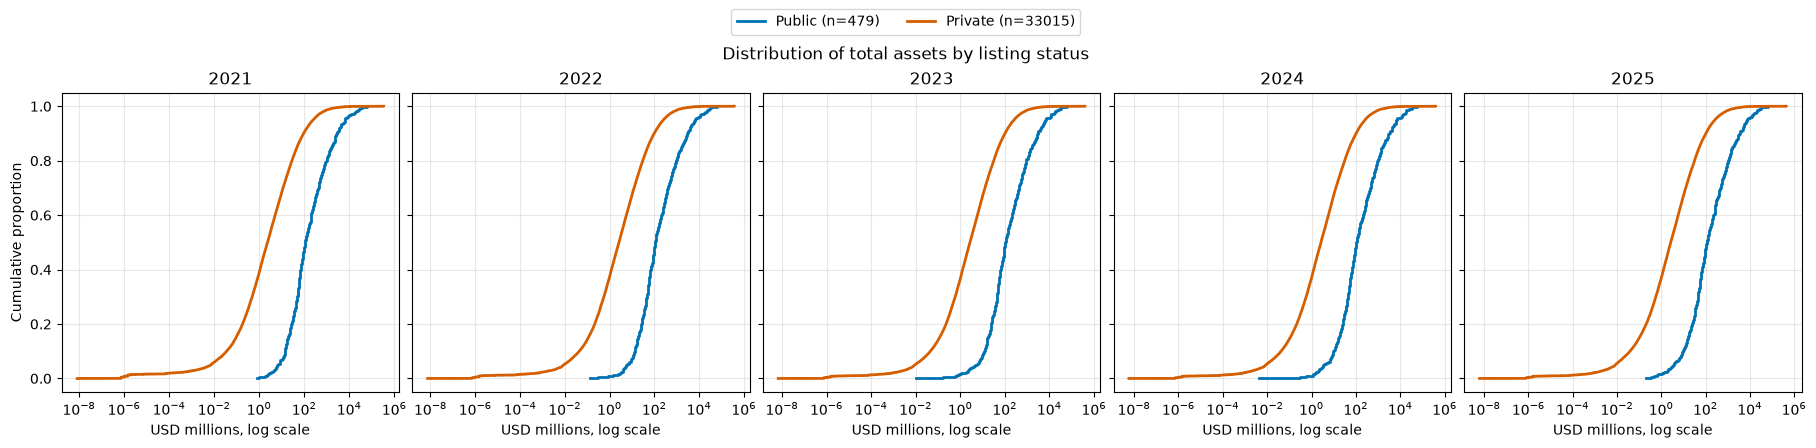

In [8]:
# Read the cleaned company-year data.
panel = pd.read_csv("data/processed/company_year_panel.csv")


def ecdf(values):
    """Create x and y coordinates for an ECDF line."""

    values = np.sort(values)
    proportions = np.arange(1, len(values) + 1) / len(values)

    return values, proportions


# Define the two dataset columns to plot.
measures = {
    "Operating revenue (Turnover) m USD": "Revenue",
    "Total assets m USD": "Total assets",
}

# Create one five-panel figure for revenue and another for assets.
for column_name, measure_name in measures.items():

    fig, axes = plt.subplots(
        nrows=1,
        ncols=5,
        figsize=(18, 4),
        sharey=True,
        constrained_layout=True,
    )

    # Make one panel for each year.
    for ax, year in zip(axes, [2021, 2022, 2023, 2024, 2025]):

        # Select positive public-company observations for this year.
        public_values = panel.loc[
            (panel["Year"] == year)
            & (panel["Listing status"] == "Listed")
            & (panel[column_name] > 0),
            column_name,
        ]

        # Select positive private-company observations for this year.
        private_values = panel.loc[
            (panel["Year"] == year)
            & (panel["Listing status"] == "Unlisted")
            & (panel[column_name] > 0),
            column_name,
        ]

        # Convert each group into ECDF coordinates.
        public_x, public_y = ecdf(public_values)
        private_x, private_y = ecdf(private_values)

        # Draw the public-company ECDF.
        ax.step(
            public_x,
            public_y,
            where="post",
            label=f"Public (n={len(public_values)})",
            color="#0072B2",
            linewidth=2,
        )

        # Draw the private-company ECDF.
        ax.step(
            private_x,
            private_y,
            where="post",
            label=f"Private (n={len(private_values)})",
            color="#D55E00",
            linewidth=2,
        )

        # A logarithmic scale makes smaller firms visible beside very large firms.
        ax.set_xscale("log")

        ax.set_title(year)
        ax.set_xlabel("USD millions, log scale")
        ax.grid(alpha=0.3)

    # Label the shared vertical axis.
    axes[0].set_ylabel("Cumulative proportion")

    # Put one shared legend above all five panels.
    handles, labels = axes[0].get_legend_handles_labels()

    fig.legend(
        handles,
        labels,
        loc="upper center",
        ncol=2,
        bbox_to_anchor=(0.5, 1.10),
    )

    fig.suptitle(
        f"Distribution of {measure_name.lower()} by listing status"
    )

    # Create a simple filename.
    filename = measure_name.lower().replace(" ", "_")

    # Save the chart.
    plt.savefig(
        f"outputs/figures/ecdf_{filename}.png",
        dpi=300,
        bbox_inches="tight",
    )